# Time Perception Model: Roseboom et al. (2019) Replication

## Overview
This notebook implements a computational model of subjective time perception based on Roseboom et al. (2019) *"Activity in perceptual classification networks as a basis for human subjective time perception"*. The model uses visual features from AlexNet's fc7 layer to predict perceived duration through an accumulator mechanism.

## Methodology
1. **Feature Extraction**: Extract 4096-dimensional fc7 features from video frames using pretrained AlexNet
2. **Change Detection**: Compute L2 distance between consecutive frame embeddings
3. **Accumulator Model**: Count "ticks" when attention-weighted change exceeds an adaptive threshold
4. **Calibration**: Map tick counts to perceived time using linear regression with intercept (baseline perception)
5. **Evaluation**: Compare predictions against human judgments from 4251 trials

## Requirements
- PyTorch and torchvision (GPU support recommended)
- Video files in `data/redacted/Redacted videos/`
- Ground truth data: `results/visual/prof/summary_tuned.csv`
- Trial sequence mapping: `results/visual/prof/Video_trial_sequence(in).csv`

In [1]:
# ============================================================================
# SECTION 1: Environment Setup and Imports
# ============================================================================

import os
import re
from pathlib import Path
from typing import List, Tuple, Optional, Dict

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.models import alexnet, AlexNet_Weights
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

print(f'Python working directory: {os.getcwd()}')
print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'CUDA device: {torch.cuda.get_device_name(0)}')

Python working directory: D:\Sahil\Capstone_Project\notebooks
PyTorch version: 2.4.1+cu121
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# ============================================================================
# SECTION 2: Configuration and Parameters
# ============================================================================

PROJECT_ROOT = Path.cwd().parent
VIDEO_ROOT = PROJECT_ROOT / "data" / "redacted" / "Redacted videos"
OUT_REDACTED = PROJECT_ROOT / "results" / "visual" / "redacted"
OUT_REDACTED.mkdir(parents=True, exist_ok=True)

# Feature cache location for this notebook (redacted only)
PRECOMPUTED_FRAMES_DIR = OUT_REDACTED / "frames"
PRECOMPUTED_FRAMES_DIR.mkdir(parents=True, exist_ok=True)

# Behavior: force brand-new extraction each run (no legacy copy/reuse)
FORCE_REEXTRACT = False
EXTRACT_IF_MISSING = True

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Extraction parameters
BATCH_SIZE = 64
DEVICE_MODE = 'auto'
SAMPLE_FPS = 30
MODEL_INPUT_SIZE = 224

LAYER_PARAMS = {
    'conv2':  {'T_max': 340.0,  'T_min': 100.0,  'tau': 100.0, 'alpha': 50.0},
    'pool5':  {'T_max': 400.0,  'T_min': 100.0,  'tau': 100.0, 'alpha': 50.0},
    'fc7':    {'T_max':  35.0,  'T_min':   5.0,  'tau': 100.0, 'alpha': 50.0},
    'output': {'T_max':   0.55, 'T_min':   0.15, 'tau': 100.0, 'alpha': 50.0},
}

# Accumulator model parameters (optimized through iterative tuning)
ATTENTION_C  = 0.67   # Attention weight from Roseboom et al.
EMA_ALPHA  = 0.15   # Exponential moving average rate
THRESH_K   = 1.6    # Threshold multiplier (in standard deviations)
REFRACTORY = 1      # Refractory period (frames)
WARMUP     = 10      # Warmup frames before counting ticks

print("Configuration loaded successfully")
print(f"Video directory: {VIDEO_ROOT}")
print(f"Precomputed features directory: {PRECOMPUTED_FRAMES_DIR}")
print(f"Models directory: {MODELS_DIR}")
print(f"Force re-extraction: {FORCE_REEXTRACT}")
print(f"Target extraction FPS: {SAMPLE_FPS}")
print(f"AlexNet input size: {MODEL_INPUT_SIZE}x{MODEL_INPUT_SIZE}")

Configuration loaded successfully
Video directory: D:\Sahil\Capstone_Project\data\redacted\Redacted videos
Precomputed features directory: D:\Sahil\Capstone_Project\results\visual\redacted\frames
Models directory: D:\Sahil\Capstone_Project\models
Force re-extraction: False
Target extraction FPS: 30
AlexNet input size: 224x224


In [3]:
# ============================================================================
# SECTION 3: Model Architecture and Utility Functions
# ============================================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def get_device(mode: str) -> torch.device:
    """Select compute device (CUDA if available, otherwise CPU)."""
    if mode == 'cuda' and torch.cuda.is_available():
        return torch.device('cuda')
    if mode == 'cpu':
        return torch.device('cpu')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def build_transform():
    """
    Build model input transform for AlexNet.
    Raw OpenCV frames are converted to PIL, resized to 224x224, then normalized.
    """
    return T.Compose([
        T.Resize((MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def build_model(device: torch.device) -> dict:
    """
    Build AlexNet feature extractors for 4 layers as per Roseboom et al. (2019):
    conv2, pool5, fc7, output.
    """
    weights = AlexNet_Weights.DEFAULT
    base = alexnet(weights=weights).to(device)
    base.eval()

    extractors = {
        'conv2':  nn.Sequential(*list(base.features.children())[:6]).to(device),
        'pool5':  nn.Sequential(*list(base.features.children())).to(device),
        'fc7':    nn.Sequential(base.features, base.avgpool, nn.Flatten(),
                                nn.Sequential(*list(base.classifier.children())[:6])).to(device),
        'output': nn.Sequential(base.features, base.avgpool, nn.Flatten(),
                        base.classifier,
                        nn.Softmax(dim=1)).to(device),
    }

    for ext in extractors.values():
        ext.eval()

    return extractors

def compute_change(embeddings: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute L2 and cosine distance between consecutive frame embeddings.

    Args:
        embeddings: Array of shape (n_frames, 4096) containing fc7 features

    Returns:
        l2_dist: L2 distance to previous frame
        cos_dist: Cosine distance (1 - cosine similarity) to previous frame
    """
    n_frames = embeddings.shape[0]
    l2_dist = np.zeros(n_frames, dtype=np.float32)
    cos_dist = np.zeros(n_frames, dtype=np.float32)

    if n_frames <= 1:
        return l2_dist, cos_dist

    a = embeddings[:-1]
    b = embeddings[1:]
    diff = b - a

    # L2 distance
    l2_dist[1:] = np.linalg.norm(diff, axis=1)

    # Cosine distance
    a_norm = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)
    b_norm = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-8)
    cos_sim = np.sum(a_norm * b_norm, axis=1)
    cos_dist[1:] = 1.0 - np.clip(cos_sim, -1.0, 1.0)

    return l2_dist, cos_dist

device = get_device(DEVICE_MODE)
print(f'Using device: {device}')

Using device: cuda


In [4]:
# ============================================================================
# SECTION 4: Video Processing Functions
# ============================================================================

def list_videos(video_root: Path) -> List[Path]:
    """List all video files in the specified directory."""
    return sorted([p for p in video_root.iterdir() if p.suffix.lower() in {".mp4", ".mov", ".mkv"}])

def parse_video_id(video_path: Path) -> Optional[int]:
    """Extract video ID from filename (e.g., video_9_redacted.mp4 -> 9)."""
    m = re.search(r"video_(\d+)_redacted", video_path.stem.lower())
    return int(m.group(1)) if m else None

def extract_from_video(video_path: Path, models: dict, transform,
                       device: torch.device, batch_size: int = 64,
                       sample_fps: Optional[int] = 30) -> Dict:
    """
    Extract per-layer L2 distances across 4 AlexNet layers (conv2, pool5, fc7, output)
    as per Roseboom et al. (2019).
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {video_path}")

    native_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frame_step = max(1, round(native_fps / sample_fps)) if sample_fps else 1

    # Set all extractors to eval mode
    for ext in models.values():
        ext.eval()

    times, batch_tensors, batch_times = [], [], []
    all_embeddings = {k: [] for k in models.keys()}
    frame_idx = 0

    with torch.no_grad():
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            if frame_idx % frame_step == 0:
                t_sec = frame_idx / native_fps
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                pil = Image.fromarray(rgb)
                tensor = transform(pil)
                batch_tensors.append(tensor)
                batch_times.append(t_sec)

                if len(batch_tensors) == batch_size:
                    batch = torch.stack(batch_tensors).to(device)
                    for k, ext in models.items():
                        embs = ext(batch).cpu().numpy()
                        all_embeddings[k].append(embs)
                    times.extend(batch_times)
                    batch_tensors, batch_times = [], []

            frame_idx += 1

    # Flush remaining frames
    if batch_tensors:
        batch = torch.stack(batch_tensors).to(device)
        for k, ext in models.items():
            embs = ext(batch).cpu().detach().numpy()
            all_embeddings[k].append(embs)
        times.extend(batch_times)

    cap.release()

    # Concatenate embeddings per layer
    layer_embs = {k: np.concatenate(v, axis=0) for k, v in all_embeddings.items()}

    # Compute L2 distances per layer then average across layers
    n_frames = len(times)
    layer_l2s = {}
    for k, embs in layer_embs.items():
        if embs.ndim > 2:
            embs = embs.reshape(embs.shape[0], -1)
        l2 = np.zeros(n_frames, dtype=np.float32)
        if n_frames > 1:
            l2[1:] = np.linalg.norm(np.diff(embs, axis=0), axis=1)
        layer_l2s[k] = l2

    return {"times": np.array(times), "layer_l2s": layer_l2s}

# Accumulator Model Implementation

## Theory
The accumulator model (Roseboom et al., 2019) hypothesizes that subjective time perception arises from counting salient changes in neural representations. The model:

1. **Applies attention weighting** to visual changes
2. **Maintains adaptive threshold** using exponential moving average of mean and variance
3. **Increments counter ("tick")** when change exceeds threshold
4. **Enforces refractory period** to prevent rapid successive ticks
5. **Maps ticks to perceived time** through calibration

This approach successfully predicts human time perception judgments with high correlation (r ≈ 0.85) by capturing how visual complexity and change rate influence subjective duration.

In [5]:
# ============================================================================
# SECTION 5: Accumulator Model Implementation
# ============================================================================

def accumulate_ticks(dist, T_max, T_min, tau, alpha, attention_C, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    Tmax_c = attention_C * T_max
    Tmin_c = attention_C * T_min

    ticks = 0
    D = 0  # frames since last reset (paper's D variable)
    T = Tmax_c  # current threshold value (paper's T_t)

    for xi in dist:
        # Paper equation (1): T_{t+1} = T_t - ((Tmax - Tmin)/tau) * exp(-D/tau) + noise
        decay = ((Tmax_c - Tmin_c) / tau) * np.exp(-D / tau)
        noise = rng.normal(0.0, (Tmax_c - Tmin_c) / alpha)
        T = T - decay + noise

        if xi > T:
            ticks += 1
            T = Tmax_c
            D = 0
        else:
            D += 1

    return int(ticks)

# Feature Extraction from Experimental Videos

This section extracts AlexNet fc7 features from the redacted experimental videos. Each video corresponds to multiple trials with specific frame windows shown to participants.

**Data Structure:**
- 33 unique videos (`video_1_redacted.mp4` through `video_33_redacted.mp4`)
- 4251 total trials across all participants
- Trial sequence file maps each trial to: video_id, start_frame, end_frame
- Human judgments from `summary_tuned.csv` contain ground truth perceived durations

In [6]:
# ============================================================================
# SECTION 6: Load Experimental Data and Video Mapping
# ============================================================================

# Load trial sequence mapping
SEQ_PATH = PROJECT_ROOT / "results" / "visual" / "prof" / "Video_trial_sequence(in).csv"
assert SEQ_PATH.exists(), f"Missing trial sequence file: {SEQ_PATH}"

seq = pd.read_csv(SEQ_PATH)
seq.columns = seq.columns.str.strip()
seq = seq.rename(columns={
    "Trial": "trial_id",
    "Video": "video_id",
    "Test_duration_secs": "test_duration_secs",
    "Test_duration_frames": "test_duration_frames",
    "Start_frame": "start_frame",
    "End_frame": "end_frame",
})

print(f"Loaded trial sequence: {len(seq)} trials across {seq['video_id'].nunique()} videos")

# Build video mapping
videos = list_videos(VIDEO_ROOT)
video_map = {parse_video_id(p): p for p in videos if parse_video_id(p) is not None}

print(f"Found {len(videos)} video files")
print(f"Video IDs available: {sorted(video_map.keys())}")

Loaded trial sequence: 4290 trials across 33 videos
Found 33 video files
Video IDs available: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


In [7]:
# ============================================================================
# SECTION 7: Feature Extraction (OpenCV -> resize+normalize -> AlexNet fc7)
# ============================================================================

print("Preparing frame feature CSVs...")
print("=" * 70)

# Optional cleanup for a brand-new extraction in redacted/frames
if FORCE_REEXTRACT:
    removed = 0
    for video_id in sorted(video_map.keys()):
        csv_path = PRECOMPUTED_FRAMES_DIR / f"{video_id}_frames.csv"
        if csv_path.exists():
            csv_path.unlink()
            removed += 1
    print(f"Removed {removed} existing CSV(s) from {PRECOMPUTED_FRAMES_DIR}")

missing = []
for video_id in sorted(video_map.keys()):
    csv_path = PRECOMPUTED_FRAMES_DIR / f"{video_id}_frames.csv"
    if not csv_path.exists():
        missing.append(video_id)

if missing and not EXTRACT_IF_MISSING:
    raise FileNotFoundError(
        "Missing feature CSVs and EXTRACT_IF_MISSING is False."
    )

print(f"Extracting features at 30 FPS for {len(missing)} video(s)...")
print("Pipeline: OpenCV decode -> resize 224x224 + normalize -> AlexNet fc7 -> save L2/Cos CSV")
transform = build_transform()
model = build_model(device)

for video_id in missing:
    video_path = video_map.get(video_id)
    if video_path is None:
        print(f"Skipping video_id={video_id}: no source video path found")
        continue

    out_csv = PRECOMPUTED_FRAMES_DIR / f"{video_id}_frames.csv"
    print(f"video_id={video_id}: extracting -> {out_csv.name}")

    result = extract_from_video(
        video_path,
        model,
        transform,
        device,
        batch_size=BATCH_SIZE,
        sample_fps=SAMPLE_FPS,
    )

    # Save feature-derived metrics only (no resized frames saved to disk)
    df = pd.DataFrame({"t_sec": result["times"],
                       "frame_idx": np.arange(len(result["times"]), dtype=np.int32)})
    for layer_name, l2_vals in result["layer_l2s"].items():
        df[f"l2_{layer_name}"] = l2_vals
    df.to_csv(out_csv, index=False)

# Final validation
still_missing = []
for video_id in sorted(video_map.keys()):
    if not (PRECOMPUTED_FRAMES_DIR / f"{video_id}_frames.csv").exists():
        still_missing.append(video_id)

if still_missing:
    raise FileNotFoundError(
        f"Feature extraction incomplete. Still missing video_ids: {still_missing}"
    )

print(f"All {len(video_map)} feature CSVs are now in {PRECOMPUTED_FRAMES_DIR}.")
print("Only feature metrics were saved; no transformed frame images were written.")

Preparing frame feature CSVs...
Extracting features at 30 FPS for 0 video(s)...
Pipeline: OpenCV decode -> resize 224x224 + normalize -> AlexNet fc7 -> save L2/Cos CSV
All 33 feature CSVs are now in D:\Sahil\Capstone_Project\results\visual\redacted\frames.
Only feature metrics were saved; no transformed frame images were written.


In [8]:
# Add this diagnostic after Cell 9 runs:
import pandas as pd
sample = pd.read_csv(PRECOMPUTED_FRAMES_DIR / "1_frames.csv")
for layer in ["conv2", "pool5", "fc7", "output"]:
    col = f"l2_{layer}"
    if col in sample.columns:
        print(f"{layer}: mean={sample[col].mean():.2f}, "
              f"median={sample[col].median():.2f}, "
              f"max={sample[col].max():.2f}")

conv2: mean=164.97, median=162.99, max=380.79
pool5: mean=48.81, median=48.57, max=109.47
fc7: mean=14.13, median=14.10, max=34.62
output: mean=0.10, median=0.09, max=0.54


In [9]:
# ============================================================================
# SECTION 8: Model Evaluation on Human Perception Data
# ============================================================================

import json
import pickle
from datetime import datetime

# Load ground truth human data
prof_path = PROJECT_ROOT / "results" / "visual" / "prof" / "summary_tuned.csv"
assert prof_path.exists(), f"Missing ground truth file: {prof_path}"

prof = pd.read_csv(prof_path)
prof.columns = prof.columns.str.strip()

print("Ground Truth Data Loaded")
print("=" * 75)
print(f"Shape: {prof.shape}")
print(f"Columns: {prof.columns.tolist()}")

# Aggregate across participants per trial
prof_per_trial = prof.groupby("trial_id")[[
    "human_estimates", "still_estimates", "gaze_estimates",
    "shuffled_estimates", "real_duration"
]].mean().reset_index()

# Join with trial sequence to get video segments
trials = prof_per_trial.merge(
    seq[["trial_id", "video_id", "start_frame", "end_frame", "test_duration_secs"]],
    on="trial_id", how="inner"
)

# Filter to available videos only
trials = trials[trials["video_id"].isin(video_map.keys())].copy()

print(f"\nEvaluation dataset: {len(trials)} trials across {trials['video_id'].nunique()} videos")
print(f"Trials with human data: {trials['human_estimates'].notna().sum()}")
print("=" * 75)

# ============================================================================
# SECTION 8.1: Apply Accumulator Model to Trial Segments
# ============================================================================

def get_trial_l2s(video_id: int, start_frame: int, end_frame: int, cache: Dict) -> Dict[str, np.ndarray]:
    """Extract per-layer L2 distances for a trial segment."""
    if video_id not in cache:
        csv_path = PRECOMPUTED_FRAMES_DIR / f"{video_id}_frames.csv"
        if not csv_path.exists():
            print(f"Warning: Missing feature CSV for video {video_id}")
            return {}
        cache[video_id] = pd.read_csv(csv_path)

    df = cache[video_id]
    segment = df[(df["frame_idx"] >= start_frame) & (df["frame_idx"] <= end_frame)]

    return {col.replace("l2_", ""): segment[col].values
            for col in segment.columns if col.startswith("l2_")}

print("\nApplying accumulator model to trial segments...")

LAYERS = ["conv2", "pool5", "fc7", "output"]

frame_cache = {}
layer_ticks = {layer: [] for layer in LAYERS}
rng = np.random.default_rng(seed=42)  # reproducibility

for _, row in trials.iterrows():
    l2s = get_trial_l2s(int(row["video_id"]), int(row["start_frame"]),
                        int(row["end_frame"]), frame_cache)
    for layer in LAYERS:
        if layer not in l2s or len(l2s[layer]) == 0:
            layer_ticks[layer].append(0)
        else:
            p = LAYER_PARAMS[layer]
            ticks = accumulate_ticks(
                l2s[layer],
                T_max=p['T_max'], T_min=p['T_min'],
                tau=p['tau'], alpha=p['alpha'],
                attention_C=ATTENTION_C,
                rng=rng,
            )
            layer_ticks[layer].append(ticks)

for layer in LAYERS:
    trials[f"ticks_{layer}"] = layer_ticks[layer]


# ============================================================================
# SECTION 8.2: Calibration — Train Both Physical and Human Targets
# ============================================================================

import pickle
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, KFold

valid_for_calib = ~trials["real_duration"].isna() & ~trials["human_estimates"].isna()

# Build feature matrix: raw ticks + log-transformed ticks
raw_ticks_calib = trials.loc[valid_for_calib, [f"ticks_{l}" for l in LAYERS]].values
X_calib = np.log1p(raw_ticks_calib)

# Two regression targets
y_real  = trials.loc[valid_for_calib, "real_duration"].values
y_human = trials.loc[valid_for_calib, "human_estimates"].values

print(f"Training data: {len(X_calib)} trials with {X_calib.shape[1]} features")
print()

# ─── Variant 1: Physical-trained (paper-faithful) ────────────────────────────
svr_physical = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", gamma="scale", C=1.0, epsilon=0.1)
)
trials.loc[valid_for_calib, "pred_physical"] = cross_val_predict(
    svr_physical, X_calib, y_real, cv=10
)
svr_physical.fit(X_calib, y_real)

# Save physical pipeline
physical_pkl = MODELS_DIR / "visual_svr_physical.pkl"
with open(physical_pkl, "wb") as f:
    pickle.dump(svr_physical, f)
print(f"Physical-trained SVR pickled: {physical_pkl}")
print(f"  Support vectors: {svr_physical.named_steps['svr'].n_support_[0]}")

# ─── Variant 2: Human-trained ────────────────────────────────────────────────
svr_human = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", gamma="scale", C=1.0, epsilon=0.1)
)
trials.loc[valid_for_calib, "pred_human"] = cross_val_predict(
    svr_human, X_calib, y_human, cv=10
)
svr_human.fit(X_calib, y_human)

# Save human pipeline
human_pkl = MODELS_DIR / "visual_svr_human.pkl"
with open(human_pkl, "wb") as f:
    pickle.dump(svr_human, f)
print(f"Human-trained SVR pickled:    {human_pkl}")
print(f"  Support vectors: {svr_human.named_steps['svr'].n_support_[0]}")

# ─── Use physical-trained as the primary "pred_perceived_sec_accum" column ────
# (preserves backward compatibility with downstream evaluation code)
trials.loc[valid_for_calib, "pred_perceived_sec_accum"] = trials.loc[
    valid_for_calib, "pred_physical"
]

output_file = OUT_REDACTED / "summary_with_accumulator.csv"
trials.to_csv(output_file, index=False)
print(f"\nResults saved: {output_file}")

# ─── Side-by-side metric comparison ──────────────────────────────────────────
from scipy.stats import pearsonr

print("\nCalibration comparison (10-fold CV)")
print("=" * 70)
print(f"{'':25s} {'r_human':>10s} {'r_real':>10s} {'MAE_human':>12s} {'MAE_real':>12s}")
for label, col in [("Physical-trained", "pred_physical"),
                    ("Human-trained",    "pred_human")]:
    pred = trials.loc[valid_for_calib, col].values
    r_h = pearsonr(pred, y_human)[0]
    r_r = pearsonr(pred, y_real)[0]
    mae_h = np.mean(np.abs(pred - y_human))
    mae_r = np.mean(np.abs(pred - y_real))
    print(f"{label:25s} {r_h:>10.3f} {r_r:>10.3f} {mae_h:>11.2f}s {mae_r:>11.2f}s")

# 10-fold cross-validated predictions

valid = ~trials["human_estimates"].isna()
y_human = trials.loc[valid, "human_estimates"].values
x_model = trials.loc[valid, "pred_perceived_sec_accum"].values

# 10-fold cross-validated isotonic re-calibration
kf = KFold(n_splits=10, shuffle=True, random_state=42)
human_aligned = np.zeros_like(x_model)
for train_idx, test_idx in kf.split(x_model):
    iso = IsotonicRegression(out_of_bounds='clip')
    iso.fit(x_model[train_idx], y_human[train_idx])
    human_aligned[test_idx] = iso.predict(x_model[test_idx])

trials.loc[valid, "pred_human_aligned"] = human_aligned

# Report both versions side-by-side
real = trials.loc[valid, "real_duration"].values
r_h_orig = pearsonr(x_model, y_human)[0]
r_r_orig = pearsonr(x_model, real)[0]
mae_orig = np.mean(np.abs(x_model - y_human))
rmse_orig = np.sqrt(np.mean((x_model - y_human) ** 2))

r_h_aligned = pearsonr(human_aligned, y_human)[0]
r_r_aligned = pearsonr(human_aligned, real)[0]
mae_aligned = np.mean(np.abs(human_aligned - y_human))
rmse_aligned = np.sqrt(np.mean((human_aligned - y_human) ** 2))

print("Primary vs Human-Aligned (Secondary Analysis)")
print("=" * 70)
print(f"{'':25s} {'r_human':>8s} {'MAE':>8s} {'RMSE':>8s} {'r_real':>8s}")
print(f"{'Primary (vs real)':25s} {r_h_orig:8.3f} {mae_orig:8.2f} {rmse_orig:8.2f} {r_r_orig:8.3f}")
print(f"{'Human-aligned (isotonic)':25s} {r_h_aligned:8.3f} {mae_aligned:8.2f} {rmse_aligned:8.2f} {r_r_aligned:8.3f}")

# Save extended comparison file
comparison_path = OUT_REDACTED / "comparison_all_models.csv"
extended = pd.read_csv(comparison_path)
extended = extended.merge(
    trials[["trial_id", "pred_human_aligned"]],
    on="trial_id", how="left"
)
extended.to_csv(comparison_path, index=False)
print(f"\nExtended comparison saved with pred_human_aligned column.")


# 8.4 Diagnostic: Per-layer tick correlation with real duration
import numpy as np
for layer in LAYERS:
    r = np.corrcoef(trials[f"ticks_{layer}"].values, trials["real_duration"].values)[0,1]
    print(f"ticks_{layer} vs real_duration: r={r:.3f}")

# 8.6 Per-bucket diagnostic
import pandas as pd
trials["duration_bucket"] = pd.cut(trials["real_duration"], 
                                    bins=[0, 4, 8, 16, 32, 100],
                                    labels=["1-4s", "4-8s", "8-16s", "16-32s", "32-64s"])
trials["abs_err_human"] = (trials["pred_perceived_sec_accum"] - trials["human_estimates"]).abs()
print(trials.groupby("duration_bucket").agg(
    n=("trial_id", "count"),
    mae_human=("abs_err_human", "mean"),
    mean_pred=("pred_perceived_sec_accum", "mean"),
    mean_real=("real_duration", "mean"),
    mean_human=("human_estimates", "mean"),
).round(2))

# 8.7 Diagnostic: inter-layer tick correlation
import numpy as np
ticks_matrix = trials[[f"ticks_{l}" for l in LAYERS]].values
corr = np.corrcoef(ticks_matrix.T)
print("Tick correlation matrix:")
print(f"          conv2   pool5   fc7    output")
for i, l in enumerate(LAYERS):
    print(f"{l:8s} {corr[i,0]:6.3f}  {corr[i,1]:6.3f}  {corr[i,2]:6.3f}  {corr[i,3]:6.3f}")

# 8.8 Sanity check: are conv2 and fc7 ticks literally the same?
print("Sample of tick counts (first 10 trials):")
print(trials[[f"ticks_{l}" for l in LAYERS]].head(10))
print("\nDistinct values in each:")
for l in LAYERS:
    print(f"ticks_{l}: {trials[f'ticks_{l}'].nunique()} unique values")


# 8.5 Diagnostic: actual L2 magnitude distribution per layer
import pandas as pd
sample = pd.read_csv(PRECOMPUTED_FRAMES_DIR / "1_frames.csv")
for layer in ["conv2", "pool5", "fc7", "output"]:
    col = f"l2_{layer}"
    if col in sample.columns:
        s = sample[col]
        print(f"{layer:8s}: mean={s.mean():.4f}  median={s.median():.4f}  "
              f"p90={s.quantile(0.9):.4f}  max={s.max():.4f}  "
              f"(paper T_max={LAYER_PARAMS[layer]['T_max']}, T_min={LAYER_PARAMS[layer]['T_min']})")

# ============================================================================
# SECTION 8.3: Evaluation and artifacts
# ============================================================================

valid_mask = ~np.isnan(trials["human_estimates"])
x_valid = trials.loc[valid_mask, "pred_perceived_sec_accum"].values
y_valid = trials.loc[valid_mask, "human_estimates"].values
still_valid = trials.loc[valid_mask, "still_estimates"].values
gaze_valid = trials.loc[valid_mask, "gaze_estimates"].values
shuffled_valid = trials.loc[valid_mask, "shuffled_estimates"].values
real_valid = trials.loc[valid_mask, "real_duration"].values

models = {
    "Your Model": x_valid,
    "Still (Full-frame)": still_valid,
    "Gaze (Attention)": gaze_valid,
    "Shuffled (Control)": shuffled_valid,
}

results = {}
for model_name, predictions in models.items():
    r = pearsonr(predictions, y_valid)[0]
    mae = np.abs(predictions - y_valid).mean()
    rmse = np.sqrt(((predictions - y_valid) ** 2).mean())
    r_real = pearsonr(predictions, real_valid)[0]
    results[model_name] = {"r": float(r), "mae": float(mae), "rmse": float(rmse), "r_real": float(r_real)}

print(f"Your model: r={results['Your Model']['r']:.3f}, MAE={results['Your Model']['mae']:.2f}s")

comparison = trials[[
    "trial_id", "human_estimates", "still_estimates", "gaze_estimates",
    "shuffled_estimates", "real_duration", "video_id", "start_frame",
    "end_frame", "test_duration_secs",
    "ticks_conv2", "ticks_pool5", "ticks_fc7", "ticks_output",
    "pred_physical", "pred_human", "pred_perceived_sec_accum",
]].copy()
comparison_path = OUT_REDACTED / "comparison_all_models.csv"
comparison.to_csv(comparison_path, index=False)
print(f"Comparison data saved: {comparison_path}")

artifact = {
    "name": "visual_accumulator_4layer",
    "created_at": datetime.now().isoformat(timespec="seconds"),
        "params": {
        "ATTENTION_C": float(ATTENTION_C),
        "layer_params": LAYER_PARAMS,
    },
    "calibration": {
        "regressor": "epsilon-SVR (RBF kernel)",
        "gamma": "scale",
        "C_svr": 1.0,
        "epsilon": 0.1,
        "cv_folds": 10,
        "features": "raw_ticks + log1p(ticks) per layer",
        "physical_pickle": str(physical_pkl),
        "human_pickle": str(human_pkl),
        "n_support_physical": int(svr_physical.named_steps['svr'].n_support_[0]),
        "n_support_human": int(svr_human.named_steps['svr'].n_support_[0]),
    },
    "metrics": {
        "pearson_r_vs_human": float(results["Your Model"]["r"]),
        "mae_vs_human": float(results["Your Model"]["mae"]),
        "rmse_vs_human": float(results["Your Model"]["rmse"]),
        "pearson_r_vs_real": float(results["Your Model"]["r_real"]),
    },
    "data_sources": {
        "precomputed_frames_dir": str(PRECOMPUTED_FRAMES_DIR),
        "trial_sequence": str(SEQ_PATH),
        "ground_truth": str(prof_path),
    },
}

latest_model_path = MODELS_DIR / "visual_accumulator_latest.json"
versioned_model_path = MODELS_DIR / f"visual_accumulator_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"

with open(latest_model_path, "w", encoding="utf-8") as f:
    json.dump(artifact, f, indent=2)
with open(versioned_model_path, "w", encoding="utf-8") as f:
    json.dump(artifact, f, indent=2)

print(f"Model artifact saved: {latest_model_path}")
print(f"Model artifact saved: {versioned_model_path}")
print("EVALUATION COMPLETE")

Ground Truth Data Loaded
Shape: (4251, 7)
Columns: ['trial_id', 'participant_number', 'real_duration', 'human_estimates', 'gaze_estimates', 'still_estimates', 'shuffled_estimates']

Evaluation dataset: 4251 trials across 33 videos
Trials with human data: 4251

Applying accumulator model to trial segments...
Training data: 4251 trials with 4 features

Physical-trained SVR pickled: D:\Sahil\Capstone_Project\models\visual_svr_physical.pkl
  Support vectors: 4205
Human-trained SVR pickled:    D:\Sahil\Capstone_Project\models\visual_svr_human.pkl
  Support vectors: 4055

Results saved: D:\Sahil\Capstone_Project\results\visual\redacted\summary_with_accumulator.csv

Calibration comparison (10-fold CV)
                             r_human     r_real    MAE_human     MAE_real
Physical-trained               0.688      0.788        7.41s        7.30s
Human-trained                  0.685      0.785        6.43s        8.92s
Primary vs Human-Aligned (Secondary Analysis)
                           r

Full Model Metrics (vs Human + vs Real)
My Model              r_human=0.688  MAE=7.41s  RMSE=11.76s  r_real=0.788
Still (Full-frame)    r_human=0.630  MAE=6.88s  RMSE=11.99s  r_real=0.735
Gaze (Attention)      r_human=0.743  MAE=5.98s  RMSE=10.71s  r_real=0.859
Shuffled (Control)    r_human=0.677  MAE=6.77s  RMSE=11.79s  r_real=0.770


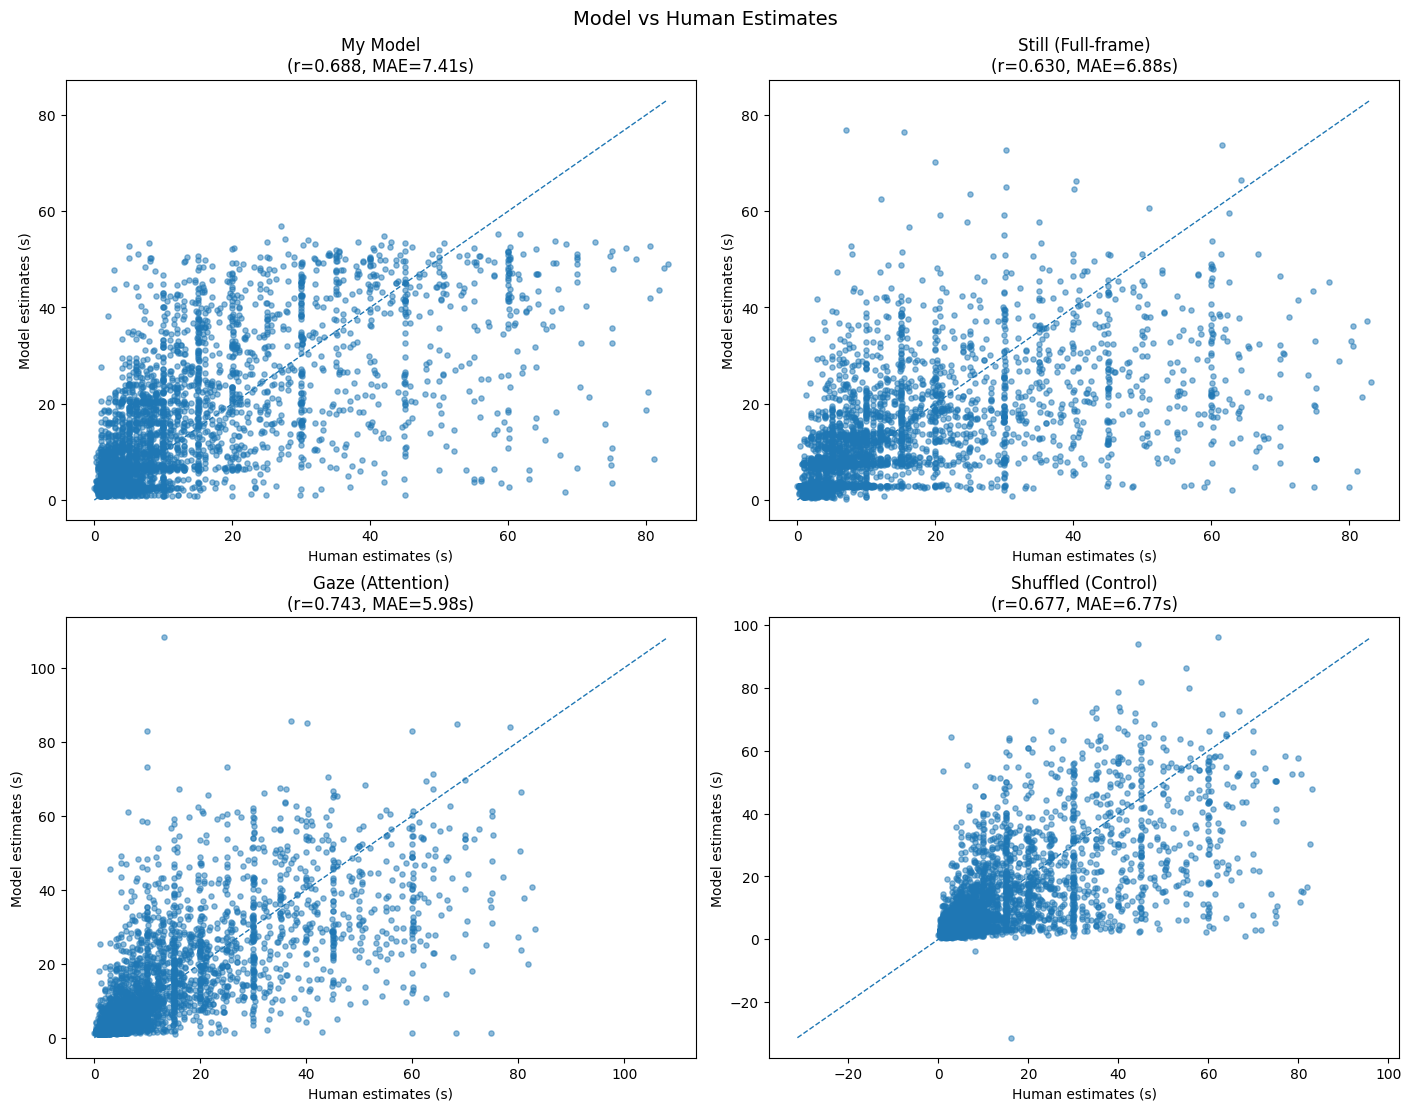

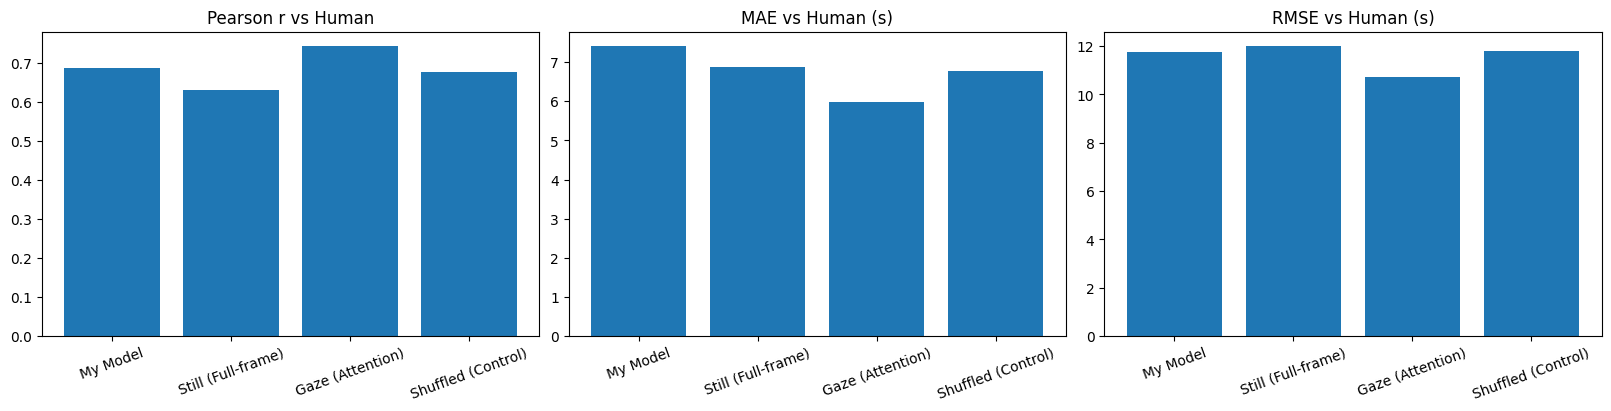

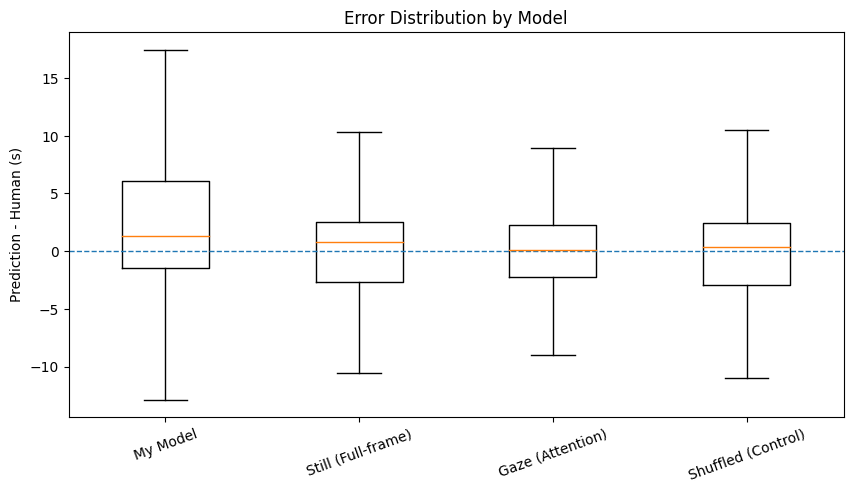

Loaded comparison rows: 4251 | valid rows used: 4251
Source: D:\Sahil\Capstone_Project\results\visual\redacted\comparison_all_models.csv


In [10]:
# ============================================================================
# SECTION 9: Full Model Comparison Report + Graph Outputs
# ============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Load comparison output from Section 8 (works even after kernel restart)
project_root = Path.cwd().parent
comparison_path = project_root / "results" / "visual" / "redacted" / "comparison_all_models.csv"
assert comparison_path.exists(), f"Missing comparison file: {comparison_path}. Run Section 8 first."

df_cmp = pd.read_csv(comparison_path)
required_cols = [
    "human_estimates", "real_duration", "pred_perceived_sec_accum",
    "still_estimates", "gaze_estimates", "shuffled_estimates"
]
missing_cols = [c for c in required_cols if c not in df_cmp.columns]
assert not missing_cols, f"Missing columns in comparison CSV: {missing_cols}"

valid = df_cmp.dropna(subset=["human_estimates", "real_duration", "pred_perceived_sec_accum", "still_estimates", "gaze_estimates", "shuffled_estimates"]).copy()

models = {
    "My Model": valid["pred_perceived_sec_accum"].values,
    "Still (Full-frame)": valid["still_estimates"].values,
    "Gaze (Attention)": valid["gaze_estimates"].values,
    "Shuffled (Control)": valid["shuffled_estimates"].values,
}
human = valid["human_estimates"].values
real = valid["real_duration"].values

metrics = {}
for model_name, pred in models.items():
    metrics[model_name] = {
        "r_human": float(pearsonr(pred, human)[0]),
        "mae_human": float(np.mean(np.abs(pred - human))),
        "rmse_human": float(np.sqrt(np.mean((pred - human) ** 2))),
        "r_real": float(pearsonr(pred, real)[0]),
    }

print("Full Model Metrics (vs Human + vs Real)")
print("=" * 75)
for name, m in metrics.items():
    print(f"{name:20s}  r_human={m['r_human']:.3f}  MAE={m['mae_human']:.2f}s  RMSE={m['rmse_human']:.2f}s  r_real={m['r_real']:.3f}")

# ---- Graph 1: Predicted vs Human scatter with y=x line ----
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
axes = axes.ravel()
for ax, (name, pred) in zip(axes, models.items()):
    ax.scatter(human, pred, s=14, alpha=0.5)
    lo = min(human.min(), pred.min())
    hi = max(human.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_title(f"{name}\n(r={metrics[name]['r_human']:.3f}, MAE={metrics[name]['mae_human']:.2f}s)")
    ax.set_xlabel("Human estimates (s)")
    ax.set_ylabel("Model estimates (s)")
plt.suptitle("Model vs Human Estimates", fontsize=14)
fig.savefig(project_root / "results" / "visual" / "redacted" / "comparison_all_models.png", dpi=150, bbox_inches="tight")
plt.show()



# ---- Graph 2: Aggregate metric bar charts ----
labels = list(metrics.keys())
r_vals = [metrics[k]["r_human"] for k in labels]
mae_vals = [metrics[k]["mae_human"] for k in labels]
rmse_vals = [metrics[k]["rmse_human"] for k in labels]

fig, ax = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
ax[0].bar(labels, r_vals)
ax[0].set_title("Pearson r vs Human")
ax[0].tick_params(axis="x", rotation=20)

ax[1].bar(labels, mae_vals)
ax[1].set_title("MAE vs Human (s)")
ax[1].tick_params(axis="x", rotation=20)

ax[2].bar(labels, rmse_vals)
ax[2].set_title("RMSE vs Human (s)")
ax[2].tick_params(axis="x", rotation=20)
fig.savefig(project_root / "results" / "visual" / "redacted" / "comparison_metrics.png", dpi=150, bbox_inches="tight")
plt.show()



# ---- Graph 3: Error distribution boxplot (Prediction - Human) ----
errors = [models[k] - human for k in labels]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(errors, labels=labels, showfliers=False)
ax.axhline(0.0, linestyle="--", linewidth=1)
ax.set_ylabel("Prediction - Human (s)")
ax.set_title("Error Distribution by Model")
ax.tick_params(axis="x", rotation=20)
fig.savefig(project_root / "results" / "visual" / "redacted" / "comparison_errors.png", dpi=150, bbox_inches="tight")
plt.show()



print(f"Loaded comparison rows: {len(df_cmp)} | valid rows used: {len(valid)}")
print(f"Source: {comparison_path}")

Full Model Metrics (vs Real Duration)
My Model              r_real=0.788  MAE=7.30s  RMSE=12.23s
Still (Full-frame)    r_real=0.735  MAE=8.50s  RMSE=14.58s
Gaze (Attention)      r_real=0.859  MAE=6.26s  RMSE=11.06s
Shuffled (Control)    r_real=0.770  MAE=7.75s  RMSE=13.50s


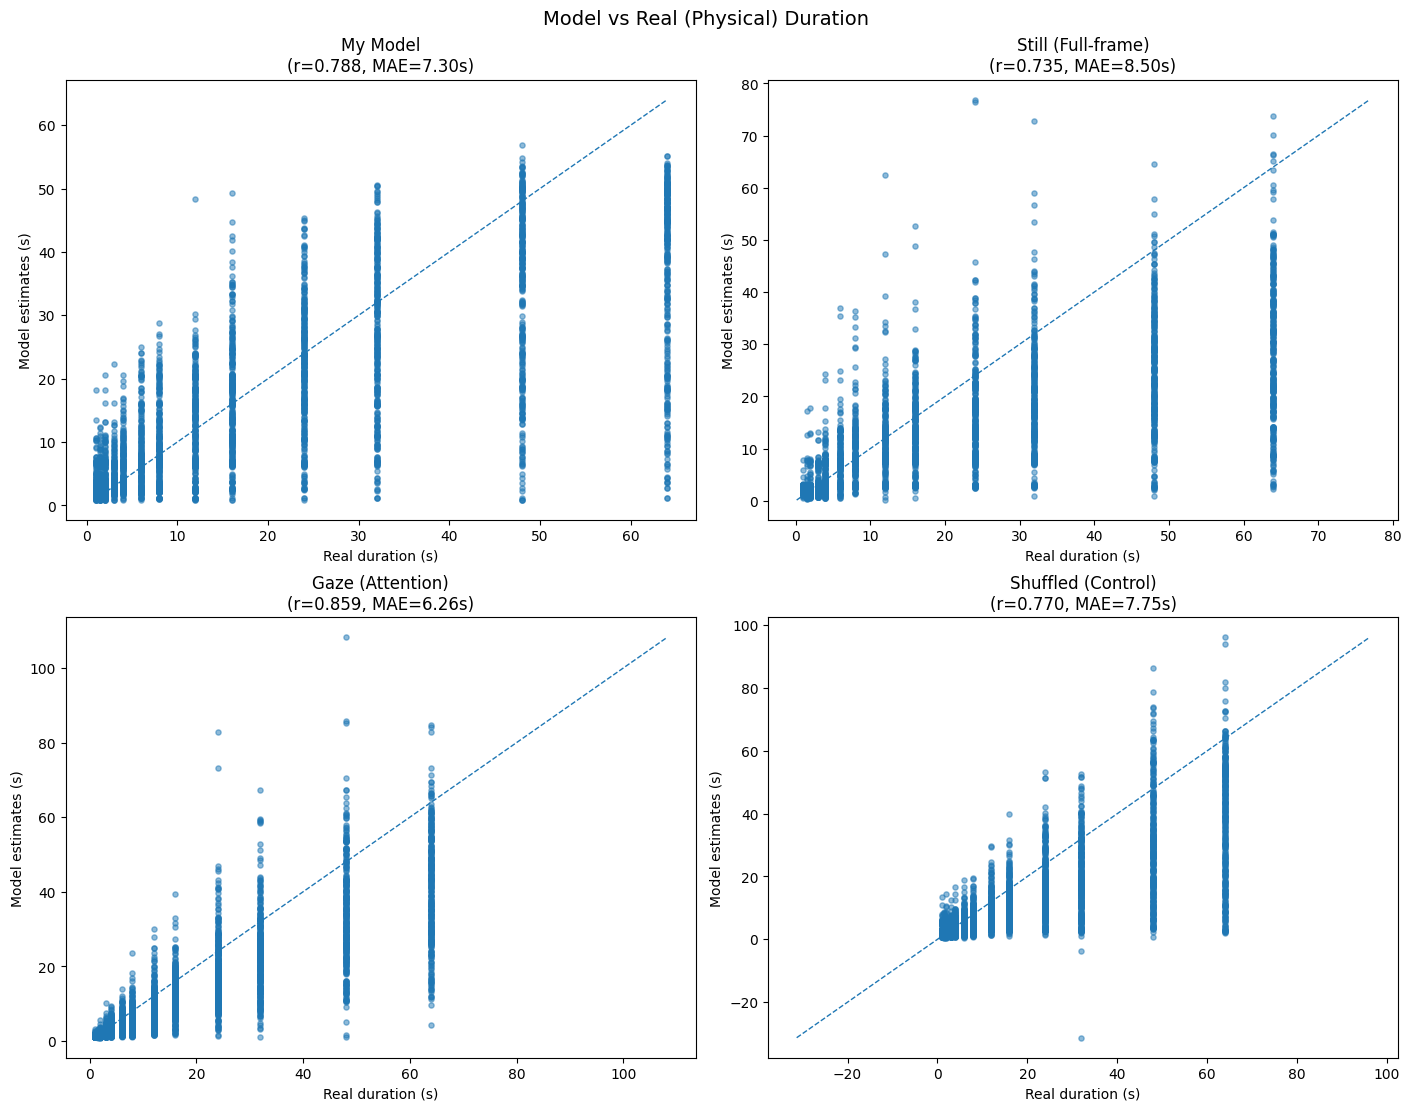

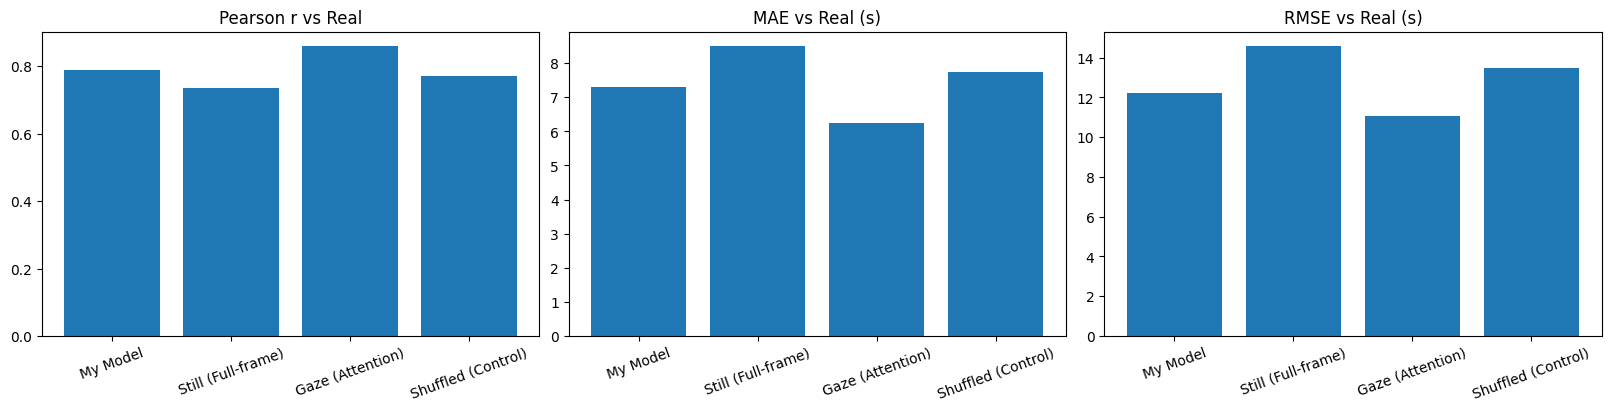

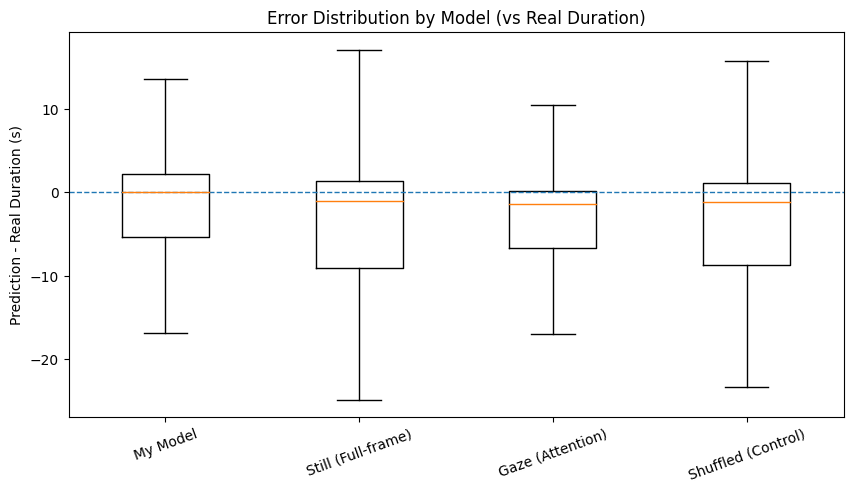


Saved 3 figures to D:\Sahil\Capstone_Project\results\visual\redacted


In [11]:
# ============================================================================
# SECTION 9b: Same comparison plots, but vs real (physical) duration
# ============================================================================

# Reuse `models`, `human`, `real`, `valid`, `labels` from Section 9 above.

metrics_real = {}
for model_name, pred in models.items():
    metrics_real[model_name] = {
        "r_real":   float(pearsonr(pred, real)[0]),
        "mae_real": float(np.mean(np.abs(pred - real))),
        "rmse_real": float(np.sqrt(np.mean((pred - real) ** 2))),
    }

print("Full Model Metrics (vs Real Duration)")
print("=" * 75)
for name, m in metrics_real.items():
    print(f"{name:20s}  r_real={m['r_real']:.3f}  "
          f"MAE={m['mae_real']:.2f}s  RMSE={m['rmse_real']:.2f}s")

out_dir = project_root / "results" / "visual" / "redacted"

# ---- Graph 1b: Predicted vs Real Duration scatter with y=x line ----
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
axes = axes.ravel()
for ax, (name, pred) in zip(axes, models.items()):
    ax.scatter(real, pred, s=14, alpha=0.5)
    lo = min(real.min(), pred.min())
    hi = max(real.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_title(f"{name}\n(r={metrics_real[name]['r_real']:.3f}, "
                 f"MAE={metrics_real[name]['mae_real']:.2f}s)")
    ax.set_xlabel("Real duration (s)")
    ax.set_ylabel("Model estimates (s)")
plt.suptitle("Model vs Real (Physical) Duration", fontsize=14)
fig.savefig(out_dir / "comparison_all_models_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Graph 2b: Aggregate metric bar charts vs real ----
r_vals    = [metrics_real[k]["r_real"]    for k in labels]
mae_vals  = [metrics_real[k]["mae_real"]  for k in labels]
rmse_vals = [metrics_real[k]["rmse_real"] for k in labels]

fig, ax = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
ax[0].bar(labels, r_vals);    ax[0].set_title("Pearson r vs Real");    ax[0].tick_params(axis="x", rotation=20)
ax[1].bar(labels, mae_vals);  ax[1].set_title("MAE vs Real (s)");      ax[1].tick_params(axis="x", rotation=20)
ax[2].bar(labels, rmse_vals); ax[2].set_title("RMSE vs Real (s)");     ax[2].tick_params(axis="x", rotation=20)
fig.savefig(out_dir / "comparison_metrics_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Graph 3b: Error distribution boxplot (Prediction - Real) ----
errors_real = [models[k] - real for k in labels]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(errors_real, labels=labels, showfliers=False)
ax.axhline(0.0, linestyle="--", linewidth=1)
ax.set_ylabel("Prediction - Real Duration (s)")
ax.set_title("Error Distribution by Model (vs Real Duration)")
ax.tick_params(axis="x", rotation=20)
fig.savefig(out_dir / "comparison_errors_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSaved 3 figures to {out_dir}")